In [13]:
"""
LLM Security Benchmark
This script measures how well an LLM classifies vulnerable and patched code pairs from CSV input.
"""

from langchain_core.prompts import ChatPromptTemplate
from langchain_ollama import ChatOllama
from sklearn.metrics import classification_report, roc_curve, auc
import matplotlib.pyplot as plt
import json
import os
import sys
import re
import time
import pandas as pd
from datetime import datetime
from pathlib import Path
from llmScan import *

In [14]:
# Create the benchmark-specific template and function
def create_benchmark_chain():
    """Create a chain specifically for benchmark boolean responses using Ollama structured output."""
    model, _ = get_model_and_chain()
    if model is None:
        return None, None

    # Reuse model metadata from llmScan
    benchmark_model_name = getattr(model, "model", PRIMARY_MODEL)
    benchmark_base_url = getattr(model, "base_url", None)

    benchmark_template = """<system>You are a security vulnerability analyzer for Python code.</system>

<user>
Your objective is to determine whether the provided Python code snippet is vulnerable or safe.
The snippet may be vulnerable or it may be safe. Classify the full snippet as a whole unit.

Examples of security vulnerabilities include:
- Unsafe use of untrusted input (e.g., from `request.args`, `request.form`, environment variables, external files)
- Dangerous function calls (e.g., `eval`, `exec`, `os.system`, `subprocess.run`, `pickle.loads`, `yaml.load`)
- Insecure file handling (e.g., `open` or `send_file` with user-controlled paths)
- Cryptographic mistakes (e.g., hardcoded keys, insecure algorithms)
- Web-specific issues (e.g., Cross-Site Scripting (XSS), CSRF vulnerabilities, Open Redirects)
- Hardcoded secrets (e.g., API keys, passwords, tokens)
- Misconfigurations (e.g., exposing debug mode, bad CORS policies)
- Omission of security features (e.g., missing input validation, hashing, secrets management)

Analyze this Python code snippet as a whole unit.
Do not score or classify line-by-line; return one final classification for the full snippet.

```python
{python_code}
```

Return only a structured JSON object with a single boolean field named `vulnerable`.
</user>
"""

    prompt = ChatPromptTemplate.from_template(benchmark_template)

    vulnerability_schema = {
        "type": "object",
        "properties": {
            "vulnerable": {"type": "boolean"}
        },
        "required": ["vulnerable"],
        "additionalProperties": False
    }

    llm_kwargs = {
        "model": benchmark_model_name,
    }
    if benchmark_base_url:
        llm_kwargs["base_url"] = benchmark_base_url

    structured_model = ChatOllama(**llm_kwargs).with_structured_output(vulnerability_schema)
    chain = prompt | structured_model

    return chain, benchmark_model_name

benchmark_chain, model_name = create_benchmark_chain()
print(f"Benchmark chain created successfully with model: {model_name}" if benchmark_chain else "Failed to create benchmark chain")

Benchmark chain created successfully with model: gemma3n:e4b


In [15]:
# Define the benchmark test function with timing for code strings
def test_vulnerabilities_benchmark(python_code_text, include_raw_response=False, include_prompt=False):
    """
    Analyze a Python code string for security vulnerabilities with a boolean-style LLM response.

    Returns:
        tuple: (success, result, model_name, scan_time)
        tuple: (success, result, model_name, scan_time, raw_response) when include_raw_response=True
        tuple: (success, result, model_name, scan_time, raw_response, prompt) when include_prompt=True
    """
    start_time = time.time()

    def _format_return(success, result, model, scan_time, raw_response=None, prompt=None):
        if include_prompt:
            return success, result, model, scan_time, raw_response, prompt
        if include_raw_response:
            return success, result, model, scan_time, raw_response
        return success, result, model, scan_time

    try:
        if benchmark_chain is None:
            scan_time = time.time() - start_time
            return _format_return(False, None, "Error: No working LLM model available", scan_time, None, None)

        # Format the prompt to capture what the LLM receives
        formatted_prompt = None
        if include_prompt:
            try:
                # Get the prompt template from the chain and format it
                prompt_obj = benchmark_chain.first
                if hasattr(prompt_obj, 'format'):
                    formatted_prompt = prompt_obj.format(python_code=str(python_code_text or ""))
            except Exception as e:
                print(f"Could not format prompt for display: {e}")

        retries = 0
        response = None
        while retries < MAX_RETRIES:
            try:
                response = benchmark_chain.invoke({"python_code": str(python_code_text or "")})
                break
            except Exception as e:
                retries += 1
                print(f"LLM invocation failed (attempt {retries}/{MAX_RETRIES}): {e}")
                if retries >= MAX_RETRIES:
                    scan_time = time.time() - start_time
                    return _format_return(False, None, model_name, scan_time, None, formatted_prompt)
                print(f"Retrying in {RETRY_DELAY} seconds...")
                time.sleep(RETRY_DELAY)

        scan_time = time.time() - start_time

        if isinstance(response, dict):
            if "vulnerable" in response and isinstance(response["vulnerable"], bool):
                return _format_return(True, response["vulnerable"], model_name, scan_time, response, formatted_prompt)
            # Backward-compatible fallback for misspelled key if a model emits it.
            if "vulenrable" in response and isinstance(response["vulenrable"], bool):
                return _format_return(True, response["vulenrable"], model_name, scan_time, response, formatted_prompt)
            print(f"Structured response missing boolean 'vulnerable': {response}")
            return _format_return(False, None, model_name, scan_time, response, formatted_prompt)

        if isinstance(response, bool):
            return _format_return(True, response, model_name, scan_time, response, formatted_prompt)
        if isinstance(response, str):
            response_lower = response.strip().lower()
            if response_lower == "true":
                return _format_return(True, True, model_name, scan_time, response, formatted_prompt)
            if response_lower == "false":
                return _format_return(True, False, model_name, scan_time, response, formatted_prompt)
            if "true" in response_lower and "false" not in response_lower:
                return _format_return(True, True, model_name, scan_time, response, formatted_prompt)
            if "false" in response_lower and "true" not in response_lower:
                return _format_return(True, False, model_name, scan_time, response, formatted_prompt)
            print(f"Ambiguous response: {response}")
            return _format_return(False, None, model_name, scan_time, response, formatted_prompt)

        print(f"Unexpected response type: {type(response)}")
        return _format_return(False, None, model_name, scan_time, response, formatted_prompt)

    except Exception:
        scan_time = time.time() - start_time
        return _format_return(False, None, model_name, scan_time, None, None)


def label_from_prediction(success, predicted_bool):
    if not success or predicted_bool is None:
        return "unknown"
    return "vulnerable" if predicted_bool else "safe"


print("test_vulnerabilities_benchmark function defined successfully!")


test_vulnerabilities_benchmark function defined successfully!


In [ ]:
# Define CSV-driven benchmark runner
def run_benchmark_from_csv(
    csv_path,
    before_col="vulnerable_code",
    after_col="fixed_code",
    verbose=True,
):
    """
    Run LLM benchmark from a CSV where each row contains vulnerable and patched code.

    Adds classification, correctness, and completion columns for before/after snippets per row.
    """
    df = pd.read_csv(csv_path)

    required = [before_col, after_col]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required column(s): {missing}")

    output_df = df.copy()

    before_predictions = []
    after_predictions = []
    before_correct = []
    after_correct = []
    before_success = []
    after_success = []
    before_completed = []
    after_completed = []
    before_times = []
    after_times = []
    model_names = []

    for idx, row in output_df.iterrows():
        before_code = row.get(before_col, "")
        after_code = row.get(after_col, "")

        b_completed, b_pred, b_model, b_time = test_vulnerabilities_benchmark(before_code)
        a_completed, a_pred, a_model, a_time = test_vulnerabilities_benchmark(after_code)

        b_label = label_from_prediction(b_completed, b_pred)
        a_label = label_from_prediction(a_completed, a_pred)

        expected_before = "vulnerable"
        expected_after = "patched"
        b_is_correct = b_label == expected_before
        a_is_correct = a_label == expected_after

        before_predictions.append(b_label)
        after_predictions.append(a_label)
        before_correct.append(b_is_correct)
        after_correct.append(a_is_correct)
        before_success.append(b_is_correct)
        after_success.append(a_is_correct)
        before_completed.append(b_completed)
        after_completed.append(a_completed)
        before_times.append(round(b_time, 3))
        after_times.append(round(a_time, 3))
        model_names.append(a_model or b_model or "unknown")

        if verbose:
            print(
                f"Row {idx + 1}: before={b_label} (expected vulnerable), "
                f"after={a_label} (expected patched)"
            )

    output_df["expected_before"] = "vulnerable"
    output_df["expected_after"] = "patched"
    output_df["llm_model"] = model_names
    output_df["llm_classification_before"] = before_predictions
    output_df["llm_classification_after"] = after_predictions
    output_df["llm_correct_before"] = before_correct
    output_df["llm_correct_after"] = after_correct
    output_df["llm_success_before"] = before_success
    output_df["llm_success_after"] = after_success
    output_df["llm_completed_before"] = before_completed
    output_df["llm_completed_after"] = after_completed
    output_df["llm_scan_time_before_seconds"] = before_times
    output_df["llm_scan_time_after_seconds"] = after_times
    output_df["llm_pair_correct"] = output_df["llm_correct_before"] & output_df["llm_correct_after"]

    return output_df

print("run_benchmark_from_csv function defined successfully!")

In [ ]:
# Run the CSV benchmark
# Update this path to your benchmark input CSV
input_csv_path = "/Users/tyler/Projects/CVEfixes/sample.csv"

print(f"Starting LLM CSV Security Benchmark on {input_csv_path}...")

df_results = run_benchmark_from_csv(input_csv_path, verbose=False)

date_stamp = datetime.now().strftime("%Y%m%d")
raw_model = str(model_name) if model_name else "LLM"
model_tag = re.sub(r"[^A-Za-z0-9]+", "", raw_model) or "LLM"
output_file = f"benchmark{model_tag}{date_stamp}.csv"
df_results.to_csv(output_file, index=False)

print(f"Benchmark completed for {len(df_results)} rows.")
print(f"Results saved to: {output_file}")

In [ ]:
# Calculate and display comprehensive metrics
print("=" * 60)
print("LLM CSV BENCHMARK RESULTS")
print("=" * 60)

total_rows = len(df_results)
print(f"Total row pairs analyzed: {total_rows}")
total_predictions = total_rows * 2 if total_rows else 0
failed_before = int((df_results["llm_completed_before"] != True).sum()) if total_rows else 0
failed_after = int((df_results["llm_completed_after"] != True).sum()) if total_rows else 0
tests_failed = failed_before + failed_after
print(f"Unsuccessful tests: {tests_failed}/{total_predictions}")

y_true = ["vulnerable"] * total_rows + ["patched"] * total_rows
y_pred_raw = df_results["llm_classification_before"].tolist() + df_results["llm_classification_after"].tolist()
y_pred = ["patched" if label == "safe" else label for label in y_pred_raw]

print("\n" + "-" * 60)
print("Classification Report (total predictions)")
print("-" * 60)
print(classification_report(y_true, y_pred, labels=["vulnerable", "patched"], target_names=["vulnerable", "patched"], zero_division=0, digits=3))

# Build confusion matrix directly from y_true/y_pred to avoid correctness-column artifacts.
pred_series = pd.Series(y_pred, name="Predicted")
pred_series = pred_series.where(pred_series.isin(["vulnerable", "patched"]), "unknown")
actual_series = pd.Series(y_true, name="Actual")

confusion_matrix = pd.crosstab(actual_series, pred_series, dropna=False)
display_cols = ["vulnerable", "patched", "unknown"]
present_cols = [c for c in display_cols if c in confusion_matrix.columns]
confusion_matrix = confusion_matrix.reindex(index=["vulnerable", "patched"], columns=present_cols, fill_value=0)
confusion_matrix.index = [f"Actual: {idx}" for idx in confusion_matrix.index]
confusion_matrix.columns = [f"Predicted: {col}" for col in confusion_matrix.columns]

print("-" * 60)
print("Confusion Matrix (total predictions)")
print("-" * 60)
print(confusion_matrix.to_string())
print("-" * 60)
print("Legend: rows=actual labels, columns=predicted labels")
print("=" * 60)

# ROC curve from hard-label predictions (unknown treated as non-vulnerable score 0).
y_true_binary = [1 if label == "vulnerable" else 0 for label in y_true]
y_score = [1 if label == "vulnerable" else 0 for label in y_pred]
if len(set(y_true_binary)) > 1:
    fpr, tpr, _ = roc_curve(y_true_binary, y_score)
    roc_auc = auc(fpr, tpr)
    print(f"ROC AUC: {roc_auc:.3f}")
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, linewidth=2, label=f"ROC curve (AUC = {roc_auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random baseline")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()
else:
    print("ROC AUC: unavailable (only one class in ground truth).")

before_completed = df_results["llm_completed_before"].mean() if total_rows else 0
after_completed = df_results["llm_completed_after"].mean() if total_rows else 0
print(f"Completion rate (before-code): {before_completed:.2%}")
print(f"Completion rate (after-code): {after_completed:.2%}")

avg_before_time = df_results["llm_scan_time_before_seconds"].mean() if total_rows else 0
avg_after_time = df_results["llm_scan_time_after_seconds"].mean() if total_rows else 0
total_before_time = df_results["llm_scan_time_before_seconds"].sum() if total_rows else 0
total_after_time = df_results["llm_scan_time_after_seconds"].sum() if total_rows else 0
total_time = total_before_time + total_after_time

print(f"\nTiming Statistics:")
print(f"Before-code - Total: {total_before_time:.3f}s | Average: {avg_before_time:.3f}s")
print(f"After-code  - Total: {total_after_time:.3f}s | Average: {avg_after_time:.3f}s")
print(f"Total scan time: {total_time:.3f}s")

if total_rows:
    models_used = sorted(df_results["llm_model"].dropna().unique().tolist())
    print(f"\nModel(s) in results: {', '.join(models_used)}")

ANALYZING BENCHMARK CSV: results/benchmarkphi414b20260416.csv
Total rows/pairs analyzed: 1551
Unsuccessful tests: 0/3102

------------------------------------------------------------
Classification Report (total predictions)
------------------------------------------------------------
              precision    recall  f1-score   support

  vulnerable      0.500     0.197     0.283      1551
     patched      0.500     0.803     0.616      1551

    accuracy                          0.500      3102
   macro avg      0.500     0.500     0.450      3102
weighted avg      0.500     0.500     0.450      3102

------------------------------------------------------------
Confusion Matrix (total predictions)
------------------------------------------------------------
                    Predicted: vulnerable  Predicted: patched
Actual: vulnerable                    306                1245
Actual: patched                       306                1245
------------------------------------------

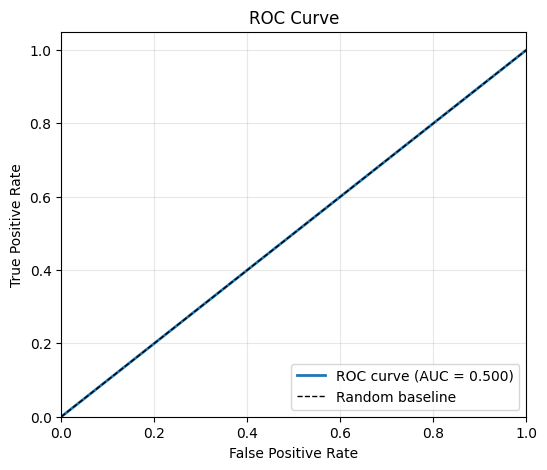

Timing summary: before avg: 5.904s | after avg: 4.758s | total scan time: 16536.646s

Model(s) in results: phi4:14b


In [22]:
# Load and analyze benchmark results from a saved CSV file
from sklearn.metrics import classification_report, roc_curve, auc
import matplotlib.pyplot as plt

def analyze_benchmark_csv(csv_path):
    """
    Load a previously generated benchmark CSV and calculate all metrics.

    Args:
        csv_path (str): Path to the benchmark results CSV file
    """
    try:
        df = pd.read_csv(csv_path)

        print("=" * 60)
        print(f"ANALYZING BENCHMARK CSV: {csv_path}")
        print("=" * 60)

        total_rows = len(df)
        print(f"Total rows/pairs analyzed: {total_rows}")

        # Auto-detect metric prefix
        if any(c.startswith("llm_") for c in df.columns):
            metric_prefix = "llm"
        elif any(c.startswith("bandit_") for c in df.columns):
            metric_prefix = "bandit"
        else:
            metric_prefix = None

        if metric_prefix is None:
            print("No supported metric columns found (expected llm_* or bandit_*).")
            return

        def col(name):
            return f"{metric_prefix}_{name}"

        if col("classification_before") in df.columns and col("classification_after") in df.columns:
            y_true = ["vulnerable"] * total_rows + ["patched"] * total_rows
            y_pred_raw = df[col("classification_before")].tolist() + df[col("classification_after")].tolist()
            y_pred = ["patched" if label == "safe" else label for label in y_pred_raw]

            if col("completed_before") in df.columns and col("completed_after") in df.columns:
                failed_before = int((df[col("completed_before")] != True).sum()) if total_rows else 0
                failed_after = int((df[col("completed_after")] != True).sum()) if total_rows else 0
                tests_failed = failed_before + failed_after
                total_predictions = len(y_true)
                print(f"Unsuccessful tests: {tests_failed}/{total_predictions}")

            print("\n" + "-" * 60)
            print("Classification Report (total predictions)")
            print("-" * 60)
            print(classification_report(y_true, y_pred, labels=["vulnerable", "patched"], target_names=["vulnerable", "patched"], zero_division=0, digits=3))

            pred_series = pd.Series(y_pred, name="Predicted")
            pred_series = pred_series.where(pred_series.isin(["vulnerable", "patched"]), "unknown")
            actual_series = pd.Series(y_true, name="Actual")

            confusion_matrix = pd.crosstab(actual_series, pred_series, dropna=False)
            display_cols = ["vulnerable", "patched", "unknown"]
            present_cols = [c for c in display_cols if c in confusion_matrix.columns]
            confusion_matrix = confusion_matrix.reindex(index=["vulnerable", "patched"], columns=present_cols, fill_value=0)
            confusion_matrix.index = [f"Actual: {idx}" for idx in confusion_matrix.index]
            confusion_matrix.columns = [f"Predicted: {col}" for col in confusion_matrix.columns]

            print("-" * 60)
            print("Confusion Matrix (total predictions)")
            print("-" * 60)
            print(confusion_matrix.to_string())
            print("-" * 60)
            print("Legend: rows=actual labels, columns=predicted labels")
            print("=" * 60)

            # ROC curve from hard-label predictions (unknown treated as non-vulnerable score 0).
            y_true_binary = [1 if label == "vulnerable" else 0 for label in y_true]
            y_score = [1 if label == "vulnerable" else 0 for label in y_pred]
            if len(set(y_true_binary)) > 1:
                fpr, tpr, _ = roc_curve(y_true_binary, y_score)
                roc_auc = auc(fpr, tpr)
                print(f"ROC AUC: {roc_auc:.3f}")
                plt.figure(figsize=(6, 5))
                plt.plot(fpr, tpr, linewidth=2, label=f"ROC curve (AUC = {roc_auc:.3f})")
                plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random baseline")
                plt.xlim([0.0, 1.0])
                plt.ylim([0.0, 1.05])
                plt.xlabel("False Positive Rate")
                plt.ylabel("True Positive Rate")
                plt.title("ROC Curve")
                plt.legend(loc="lower right")
                plt.grid(alpha=0.3)
                plt.show()
            else:
                print("ROC AUC: unavailable (only one class in ground truth).")

        # Timing summary (kept compact to avoid duplicate per-side stats)
        timing_parts = []
        if col("scan_time_before_seconds") in df.columns:
            avg_before_time = df[col("scan_time_before_seconds")].mean() if total_rows else 0
            timing_parts.append(f"before avg: {avg_before_time:.3f}s")
        if col("scan_time_after_seconds") in df.columns:
            avg_after_time = df[col("scan_time_after_seconds")].mean() if total_rows else 0
            timing_parts.append(f"after avg: {avg_after_time:.3f}s")
        if col("scan_time_before_seconds") in df.columns and col("scan_time_after_seconds") in df.columns:
            total_time = df[col("scan_time_before_seconds")].sum() + df[col("scan_time_after_seconds")].sum()
            timing_parts.append(f"total scan time: {total_time:.3f}s")
        if timing_parts:
            print("Timing summary: " + " | ".join(timing_parts))

        # Model information (if present)
        model_col = f"{metric_prefix}_model"
        if model_col in df.columns:
            models_used = sorted(df[model_col].dropna().unique().tolist())
            if models_used:
                print(f"\nModel(s) in results: {', '.join(models_used)}")

        print("=" * 60)

    except FileNotFoundError:
        print(f"Error: Could not find file at {csv_path}")
    except Exception as e:
        print(f"Error reading CSV: {e}")

input_csv_path = "results/benchmarkphi414b20260416.csv"

# Check if file exists before running
import os
if os.path.exists(input_csv_path):
    analyze_benchmark_csv(input_csv_path)
else:
    print(f"File not found: {input_csv_path}")
    print("Available CSV files in results/:")
    if os.path.exists("results"):
        for f in os.listdir("results"):
            if f.endswith(".csv"):
                print(f"  - {f}")

In [ ]:
# Optional compact summary export
summary = {
    "total_row_pairs": len(df_results),
    "before_accuracy": float(df_results["llm_correct_before"].mean()) if len(df_results) else 0.0,
    "after_accuracy": float(df_results["llm_correct_after"].mean()) if len(df_results) else 0.0,
    "pair_accuracy": float(df_results["llm_pair_correct"].mean()) if len(df_results) else 0.0,
    "before_success_rate": float(df_results["llm_success_before"].mean()) if len(df_results) else 0.0,
    "after_success_rate": float(df_results["llm_success_after"].mean()) if len(df_results) else 0.0,
    "before_completed_rate": float(df_results["llm_completed_before"].mean()) if len(df_results) else 0.0,
    "after_completed_rate": float(df_results["llm_completed_after"].mean()) if len(df_results) else 0.0,
    "tests_failed": int((df_results["llm_completed_before"] != True).sum() + (df_results["llm_completed_after"] != True).sum()) if len(df_results) else 0,
    "unknown_before": int((df_results["llm_classification_before"] == "unknown").sum()) if len(df_results) else 0,
    "unknown_after": int((df_results["llm_classification_after"] == "unknown").sum()) if len(df_results) else 0,
}

summary_df = pd.DataFrame([summary])
summary_file = "llm_csv_benchmark_summary.csv"
summary_df.to_csv(summary_file, index=False)
print(f"Summary metrics saved to: {summary_file}")

In [ ]:
# Debug LLM Input/Output from CSV rows
def debug_llm_from_csv(
    csv_path,
    sample_pairs=1,
    start_row=0,
    random_sample=False,
    random_seed=42,
    before_col="vulnerable_code",
    after_col="fixed_code",
    preview_chars=240,
):
    df = pd.read_csv(csv_path)
    if df.empty:
        print("CSV is empty.")
        return

    total_rows = len(df)
    sample_pairs = int(sample_pairs) if sample_pairs is not None else 1
    if sample_pairs <= 0:
        print("sample_pairs must be >= 1")
        return

    if random_sample:
        sample_n = min(sample_pairs, total_rows)
        sampled_df = df.sample(n=sample_n, random_state=random_seed)
        selected_indices = sampled_df.index.tolist()
    else:
        if start_row < 0 or start_row >= total_rows:
            print(f"start_row {start_row} is out of range (0-{total_rows-1})")
            return
        end_row = min(start_row + sample_pairs, total_rows)
        selected_indices = list(range(start_row, end_row))

    print("=" * 60)
    print(f"LLM CSV DEBUG | Testing {len(selected_indices)} pair(s)")
    print(f"Columns: before={before_col}, after={after_col}")
    print("=" * 60)

    for i, row_index in enumerate(selected_indices, start=1):
        row = df.iloc[row_index]
        before_code = str(row.get(before_col, "") or "")
        after_code = str(row.get(after_col, "") or "")

        print("-" * 60)
        print(f"Sample {i}/{len(selected_indices)} | Row {row_index + 1}")
        print(f"Source lengths: before={len(before_code)} chars, after={len(after_code)} chars")
        print(f"Line counts: before={before_code.count(chr(10)) + 1 if before_code else 0}, after={after_code.count(chr(10)) + 1 if after_code else 0}")
        print(f"Before/after identical: {before_code == after_code}")
        print(f"Before preview:\n{before_code[:preview_chars]}")
        if len(before_code) > preview_chars:
            print("... [before preview truncated]")
        print(f"After preview:\n{after_code[:preview_chars]}")
        if len(after_code) > preview_chars:
            print("... [after preview truncated]")

        b_completed, b_pred, b_model, b_time, b_raw, b_prompt = test_vulnerabilities_benchmark(before_code, include_raw_response=True, include_prompt=True)
        a_completed, a_pred, a_model, a_time, a_raw, a_prompt = test_vulnerabilities_benchmark(after_code, include_raw_response=True, include_prompt=True)
        b_label = label_from_prediction(b_completed, b_pred)
        a_label = label_from_prediction(a_completed, a_pred)
        b_success = b_label == "vulnerable"
        a_success = a_label == "safe"

        print("\n" + "=" * 60)
        print("FULL PROMPT RECEIVED BY LLM (BEFORE CODE):")
        print("=" * 60)
        if b_prompt:
            print(b_prompt)
        else:
            print("[Prompt unavailable]")
        print("=" * 60)

        print(f"Before expected: vulnerable | predicted: {b_label} | success: {b_success} | completed: {b_completed} | model: {b_model} | time: {b_time:.3f}s")
        print(f"Before raw response: {repr(b_raw)}")
        
        print("\n" + "=" * 60)
        print("FULL PROMPT RECEIVED BY LLM (AFTER CODE):")
        print("=" * 60)
        if a_prompt:
            print(a_prompt)
        else:
            print("[Prompt unavailable]")
        print("=" * 60)
        
        print(f"After expected: safe       | predicted: {a_label} | success: {a_success} | completed: {a_completed} | model: {a_model} | time: {a_time:.3f}s")
        print(f"After raw response: {repr(a_raw)}")

# Example debug usage
input_csv_path = "data1551redacted.csv"
# debug_llm_from_csv(input_csv_path, sample_pairs=3, start_row=0)
debug_llm_from_csv(input_csv_path, sample_pairs=5, random_sample=True, random_seed=42, preview_chars=240)